### Linear-Regression-Machine-Learning-Project

#### Install the required Python libraries

In [78]:
!pip install pandas scikit-learn

Defaulting to user installation because normal site-packages is not writeable


#### Import Pandas and load the laptop dataset

In [79]:
import pandas as pd
import os

In [80]:
os.getcwd()

'C:\\Users\\pmgho\\OneDrive\\Desktop\\Machine_Learning'

In [81]:
os.chdir("C:\\Users\\pmgho\\OneDrive\\Desktop\\Machine_Learning")

In [82]:
os.getcwd()

'C:\\Users\\pmgho\\OneDrive\\Desktop\\Machine_Learning'

In [83]:
df = pd.read_csv("laptops.csv")
df

,brand,model,device_category,price,rating,cpu_brand,cpu_family,cpu_series,cpu_model,cpu_suffix,...,display_height_px,display_size_inch,gpu_brand,gpu_series,gpu_model,gpu_vram_gb,gpu_type,os_name,warranty_years,Unnamed: 24
0,lenovo,Lenovo Legion Pro 5 16IAX10 83F3007CIN Gaming,Gaming,189990,84,Intel,Core Ultra,Core Ultra 7,255HX,HX,...,1600,16,NVIDIA,GeForce RTX,RTX 5060,8.0,Dedicated,Windows,1,NaN
1,lenovo,Lenovo IdeaPad Slim 3 83K100HSIN,Thin & Light,62350,54,Intel,Core,Core I5,13420H,H,...,1080,15,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN
2,asus,Asus Vivobook Go 15 E1504FA-BQ2343WS,Thin & Light,34990,51,AMD,Ryzen,Ryzen 3,7320U,U,...,1080,15,AMD,Radeon,Radeon,NaN,Integrated,Windows,1,NaN
3,lenovo,Lenovo V14 G3 82TS00JGUS,General,56990,48,Intel,Core,Core I7,1255U,U,...,1080,14,Intel,Iris Xe,Iris Xe Graphics,NaN,Integrated,Windows,1,NaN
4,dell,Dell DC 14250 ODC1425000401RINS1,General,69990,52,Intel,Core,Core 5,120U,U,...,1080,14,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
987,lenovo,Lenovo IdeaPad Slim 5 14IMH9 83DA0002IN,Thin & Light,88999,59,Intel,Core Ultra,Core Ultra 5,125H,H,...,1200,14,Intel,Arc,Arc Graphics,NaN,Integrated,Windows,1,NaN
988,asus,Asus Vivobook S 15 OLED 2024 S5507QAD-MA751WS,Thin & Light,84834,53,Snapdragon,Snapdragon,Snapdragon X,Elite X1E 78 100,NaN,...,1620,15,Qualcomm,Adreno,Adreno GPU,NaN,Integrated,Windows,1,NaN
989,asus,Asus Vivobook 15 X1504VA-NJ540WS,Thin & Light,48990,54,Intel,Core,Core I5,1335U,U,...,1080,15,Intel,Iris Xe,Iris Xe Graphics,NaN,Integrated,Windows,1,NaN
990,lenovo,Lenovo IdeaPad 1 14IGL7 82V6009LIN,General,28802,46,Intel,Celeron,Celeron,N4020,NaN,...,768,14,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN


In [84]:
df.head()

,brand,model,device_category,price,rating,cpu_brand,cpu_family,cpu_series,cpu_model,cpu_suffix,...,display_height_px,display_size_inch,gpu_brand,gpu_series,gpu_model,gpu_vram_gb,gpu_type,os_name,warranty_years,Unnamed: 24
0,lenovo,Lenovo Legion Pro 5 16IAX10 83F3007CIN Gaming,Gaming,189990,84,Intel,Core Ultra,Core Ultra 7,255HX,HX,...,1600,16,NVIDIA,GeForce RTX,RTX 5060,8.0,Dedicated,Windows,1,NaN
1,lenovo,Lenovo IdeaPad Slim 3 83K100HSIN,Thin & Light,62350,54,Intel,Core,Core I5,13420H,H,...,1080,15,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN
2,asus,Asus Vivobook Go 15 E1504FA-BQ2343WS,Thin & Light,34990,51,AMD,Ryzen,Ryzen 3,7320U,U,...,1080,15,AMD,Radeon,Radeon,NaN,Integrated,Windows,1,NaN
3,lenovo,Lenovo V14 G3 82TS00JGUS,General,56990,48,Intel,Core,Core I7,1255U,U,...,1080,14,Intel,Iris Xe,Iris Xe Graphics,NaN,Integrated,Windows,1,NaN
4,dell,Dell DC 14250 ODC1425000401RINS1,General,69990,52,Intel,Core,Core 5,120U,U,...,1080,14,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN


#### Check the number of rows and columns in the dataset

In [87]:
print(df.shape)

(992, 25)


#### Display dataset information and data types

In [88]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 992 entries, 0 to 991
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              992 non-null    object 
 1   model              992 non-null    object 
 2   device_category    992 non-null    object 
 3   price              992 non-null    int64  
 4   rating             992 non-null    int64  
 5   cpu_brand          992 non-null    object 
 6   cpu_family         992 non-null    object 
 7   cpu_series         992 non-null    object 
 8   cpu_model          992 non-null    object 
 9   cpu_suffix         861 non-null    object 
 10  cpu_core_count     992 non-null    int64  
 11  cpu_thread_count   992 non-null    int64  
 12  ram_gb             992 non-null    int64  
 13  storage_gb         992 non-null    int64  
 14  display_width_px   992 non-null    int64  
 15  display_height_px  992 non-null    int64  
 16  display_size_inch  992 non

#### Count the available GPU types

In [89]:
df["gpu_type"].value_counts()

gpu_type
Integrated    692
Dedicated     292
Name: count, dtype: int64

In [90]:
df["gpu_vram_gb"].value_counts()

gpu_vram_gb
6.0     92
8.0     87
4.0     81
12.0    15
16.0    11
24.0     5
2.0      1
Name: count, dtype: int64

#### Find records with missing GPU type values

In [91]:
missing_gpu = df[df["gpu_type"].isnull()]
missing_gpu

,brand,model,device_category,price,rating,cpu_brand,cpu_family,cpu_series,cpu_model,cpu_suffix,...,display_height_px,display_size_inch,gpu_brand,gpu_series,gpu_model,gpu_vram_gb,gpu_type,os_name,warranty_years,Unnamed: 24
5,dell,Dell 14 Inspiron 5440 (100UU / 16GB / 512GB / ...,General,37800,50,Intel,Core,Core I3,100U,U,...,1080,14,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN
122,hp,HP ZBook Firefly 16 8F6K1PA Workstation,General,132499,62,Intel,Core,Core I7,1255U,U,...,1200,16,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN
759,hp,HP ZBook Firefly 14 G10 8F6C8PA Workstation,General,132499,66,Intel,Core,Core I7,1355U,U,...,1200,14,NaN,NaN,NaN,NaN,NaN,Windows,3,NaN
765,apple,Apple 2024 MacBook Air 15,Thin & Light,104994,56,Apple,M-Series,M3,M3,NaN,...,1864,15,NaN,NaN,NaN,NaN,NaN,Mac,1,NaN
767,apple,Apple MacBook Air 15 2024,Thin & Light,154287,60,Apple,M-Series,M3,M3,NaN,...,1864,15,NaN,NaN,NaN,NaN,NaN,Mac,1,NaN
801,dell,Dell Inspiron 7440 2 in 1,Convertible,75990,62,Intel,Core,Core I5,1334U,U,...,1080,14,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN
822,dell,Dell 14 Inspiron 7440 2in1,General,85512,64,Intel,Core,Core 7,150U,U,...,1400,14,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN
843,dell,Dell Inspiron 7440 2in1,General,61990,56,Intel,Core,Core 3,100U,U,...,1400,14,NaN,NaN,NaN,NaN,NaN,Windows,1,NaN


#### Remove records with missing GPU type values

In [92]:
df_cleaned = df.dropna(subset=["gpu_type"])
df_cleaned

,brand,model,device_category,price,rating,cpu_brand,cpu_family,cpu_series,cpu_model,cpu_suffix,...,display_height_px,display_size_inch,gpu_brand,gpu_series,gpu_model,gpu_vram_gb,gpu_type,os_name,warranty_years,Unnamed: 24
0,lenovo,Lenovo Legion Pro 5 16IAX10 83F3007CIN Gaming,Gaming,189990,84,Intel,Core Ultra,Core Ultra 7,255HX,HX,...,1600,16,NVIDIA,GeForce RTX,RTX 5060,8.0,Dedicated,Windows,1,NaN
1,lenovo,Lenovo IdeaPad Slim 3 83K100HSIN,Thin & Light,62350,54,Intel,Core,Core I5,13420H,H,...,1080,15,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN
2,asus,Asus Vivobook Go 15 E1504FA-BQ2343WS,Thin & Light,34990,51,AMD,Ryzen,Ryzen 3,7320U,U,...,1080,15,AMD,Radeon,Radeon,NaN,Integrated,Windows,1,NaN
3,lenovo,Lenovo V14 G3 82TS00JGUS,General,56990,48,Intel,Core,Core I7,1255U,U,...,1080,14,Intel,Iris Xe,Iris Xe Graphics,NaN,Integrated,Windows,1,NaN
4,dell,Dell DC 14250 ODC1425000401RINS1,General,69990,52,Intel,Core,Core 5,120U,U,...,1080,14,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
987,lenovo,Lenovo IdeaPad Slim 5 14IMH9 83DA0002IN,Thin & Light,88999,59,Intel,Core Ultra,Core Ultra 5,125H,H,...,1200,14,Intel,Arc,Arc Graphics,NaN,Integrated,Windows,1,NaN
988,asus,Asus Vivobook S 15 OLED 2024 S5507QAD-MA751WS,Thin & Light,84834,53,Snapdragon,Snapdragon,Snapdragon X,Elite X1E 78 100,NaN,...,1620,15,Qualcomm,Adreno,Adreno GPU,NaN,Integrated,Windows,1,NaN
989,asus,Asus Vivobook 15 X1504VA-NJ540WS,Thin & Light,48990,54,Intel,Core,Core I5,1335U,U,...,1080,15,Intel,Iris Xe,Iris Xe Graphics,NaN,Integrated,Windows,1,NaN
990,lenovo,Lenovo IdeaPad 1 14IGL7 82V6009LIN,General,28802,46,Intel,Celeron,Celeron,N4020,NaN,...,768,14,Intel,UHD,UHD Graphics,NaN,Integrated,Windows,1,NaN


#### Check the shape of the cleaned dataset

In [93]:
df_cleaned.shape

(984, 25)

#### Display all column names

In [94]:
df_cleaned.columns

Index(['brand', 'model', 'device_category', 'price', 'rating', 'cpu_brand',
       'cpu_family', 'cpu_series', 'cpu_model', 'cpu_suffix', 'cpu_core_count',
       'cpu_thread_count', 'ram_gb', 'storage_gb', 'display_width_px',
       'display_height_px', 'display_size_inch', 'gpu_brand', 'gpu_series',
       'gpu_model', 'gpu_vram_gb', 'gpu_type', 'os_name', 'warranty_years',
       'Unnamed: 24'],
      dtype='object')

In [95]:
df_cleaned.count()

brand                984
model                984
device_category      984
price                984
rating               984
cpu_brand            984
cpu_family           984
cpu_series           984
cpu_model            984
cpu_suffix           855
cpu_core_count       984
cpu_thread_count     984
ram_gb               984
storage_gb           984
display_width_px     984
display_height_px    984
display_size_inch    984
gpu_brand            984
gpu_series           984
gpu_model            984
gpu_vram_gb          292
gpu_type             984
os_name              984
warranty_years       984
Unnamed: 24            0
dtype: int64

#### Select the GPU VRAM column

In [96]:
gpu_vram_gb = df_cleaned["gpu_vram_gb"]

#### Display the unique GPU VRAM values

In [97]:
gpu_vram_gb.unique()

array([ 8., nan,  6., 24., 16.,  4., 12.,  2.])

#### Count the occurrences of each GPU VRAM value

In [98]:
gpu_vram_gb.value_counts()

gpu_vram_gb
6.0     92
8.0     87
4.0     81
12.0    15
16.0    11
24.0     5
2.0      1
Name: count, dtype: int64

#### Select input features

In [99]:
features = [
    "cpu_core_count",
    "cpu_thread_count",
    "ram_gb",
    "storage_gb",
    "gpu_type",
    "gpu_model",
]

In [100]:
X = df_cleaned[features]

#### Select the target price

In [101]:
y = df_cleaned['price']

#### Preview the input feature data

In [102]:
X.head()

,cpu_core_count,cpu_thread_count,ram_gb,storage_gb,gpu_type,gpu_model
0,20,20,32,1024,Dedicated,RTX 5060
1,8,12,16,1024,Integrated,UHD Graphics
2,4,8,16,512,Integrated,Radeon
3,10,12,16,512,Integrated,Iris Xe Graphics
4,10,12,16,512,Integrated,UHD Graphics


#### Preview the target price data

In [103]:
y.head()

0    189990
1     62350
2     34990
3     56990
4     69990
Name: price, dtype: int64

#### Check missing values in the input features

In [104]:
print("Missing values in each feature:")
print(X.isnull().sum())

Missing values in each feature:
cpu_core_count      0
cpu_thread_count    0
ram_gb              0
storage_gb          0
gpu_type            0
gpu_model           0
dtype: int64


In [105]:
print("\nTotal missing values:", X.isnull().sum().sum())


Total missing values: 0


#### Separate numerical and categorical features

In [106]:
numerical_features = [
    "cpu_core_count",
    "cpu_thread_count",
    "ram_gb",
    "storage_gb"
]

In [107]:
categorical_features = [
    "gpu_type",
    "gpu_model"
]

#### Create preprocessing for categorical features

In [108]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [55]:
from sklearn.linear_model import LinearRegression

In [109]:
# Transform categorical features into numerical columns
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

#### Split the dataset into training and testing sets

In [110]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (787, 6)
Testing features: (197, 6)
Training target: (787,)
Testing target: (197,)


#### Create the Linear Regression model pipeline

In [111]:
from sklearn.linear_model import LinearRegression
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

In [112]:
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

#### Train the Linear Regression model

In [113]:
model.fit(X_train, y_train)
print("Model training completed successfully.")

Model training completed successfully.


#### Generate price predictions for the test data

In [114]:
y_pred = model.predict(X_test)

In [62]:
y_pred

array([ 34350.29701427,  71077.06396421, 137881.11680864,  73382.977542  ,
        81650.11376041, 196161.9290411 , 112817.03215372,  60129.60016715,
        39821.2516604 ,  89801.39598519, 116452.7389642 ,  69782.3387881 ,
       101841.97472092,  97277.16952501,  52995.67483405,  88830.44786834,
        51622.19893871,  35434.27811796,  21604.31410969,  95302.73492417,
        34350.29701427,  69308.44034058,  37097.24880494, 130955.72411873,
        86780.94314617, 113593.86114006, 221887.49625252,  54658.64552102,
        54658.64552102,  93668.37711354,  26304.66772614, 217558.65694208,
       112817.03215372, 101172.12128817,  35434.27811796, 110070.08036305,
        35434.27811796, 149956.00975565, 145273.35061316,  97248.07865803,
       130066.96909891,  57405.59731169,  51911.69373035,  72055.39213125,
        35434.27811796,  62493.68747758,  88830.44786834,  55742.62662471,
        57405.59731169,  52995.67483405, 170729.46949974,  62125.28522587,
        62125.28522587,  

#### Compare sample actual and predicted prices

In [115]:
print("Actual prices:")
print(y_test.head(10).to_list())

Actual prices:
[34750, 68475, 210990, 79990, 75990, 288490, 89999, 55900, 35190, 64990]


In [116]:
print("\nPredicted prices:")
print(y_pred[:10].round(2))


Predicted prices:
[ 34350.3   71077.06 137881.12  73382.98  81650.11 196161.93 112817.03
  60129.6   39821.25  89801.4 ]


#### Plot actual prices against predicted prices

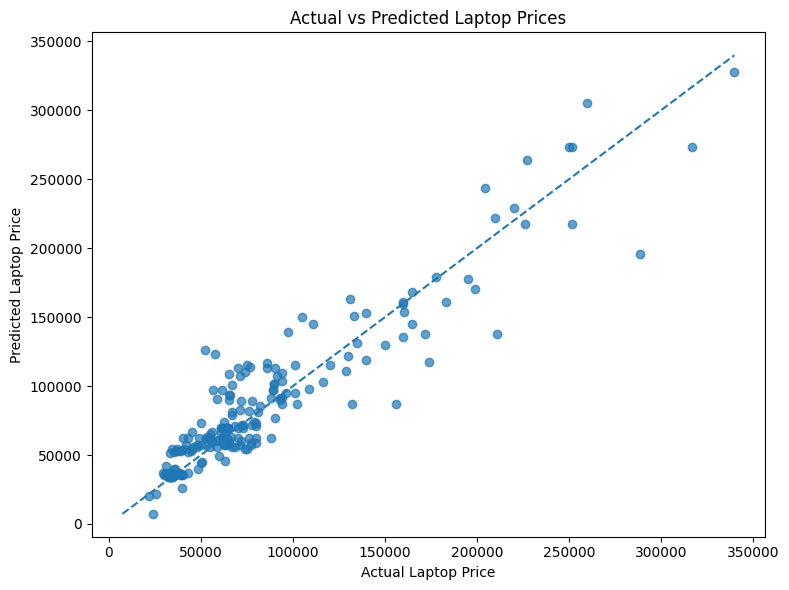

In [117]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line: perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Laptop Price")
plt.ylabel("Predicted Laptop Price")
plt.title("Actual vs Predicted Laptop Prices")

plt.tight_layout()
plt.show()

#### Evaluate the model using MAE, MSE, and R-squared

In [118]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 14557.09
Mean Squared Error (MSE): 447533510.99
R² Score: 0.8672


#### Select an expanded set of input features and target price

In [119]:
features = [
    "brand",
    "cpu_core_count",
    "cpu_thread_count",
    "cpu_model",
    "ram_gb",
    "storage_gb",
    "gpu_type",
    "gpu_model",
    "display_size_inch",
    "display_width_px",
    "display_height_px",
    "device_category"
]

X = df_cleaned[features]
y = df_cleaned["price"]

#### Separate the expanded features into numerical and categorical groups

In [120]:
numerical_features = [
    "cpu_core_count",
    "cpu_thread_count",
    "ram_gb",
    "storage_gb",
    "display_size_inch",
    "display_width_px",
    "display_height_px"
]

categorical_features = [
    "brand",
    "cpu_model",
    "gpu_type",
    "gpu_model",
    "device_category"
]

#### Split the expanded dataset into training and testing sets

In [121]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (787, 12)
Testing features: (197, 12)
Training target: (787,)
Testing target: (197,)


#### Build preprocessing pipelines for numerical and categorical features

In [122]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

# Preprocessing for numerical features
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Preprocessing for categorical features
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Apply the correct preprocessing to each feature group
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


#### Build and train the improved Linear Regression pipeline

In [126]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)
model.fit(X_train, y_train)
print("Improved Linear Regression model trained successfully.")

Improved Linear Regression model trained successfully.


#### Generate predictions and compare sample actual and predicted prices

In [127]:
y_pred = model.predict(X_test)

print("First 10 actual prices:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

First 10 actual prices:
[34750, 68475, 210990, 79990, 75990, 288490, 89999, 55900, 35190, 64990]

First 10 predicted prices:
[ 35056.59693316  79639.30757092 167755.06100285  46106.1212557
  77219.67344189 218347.06688004 116517.73644529  56250.11047273
  32047.14327307  88575.30343224]


#### Plot actual prices against predicted prices for the improved model

Text(0.5, 1.0, 'Actual vs Predicted Laptop Prices')

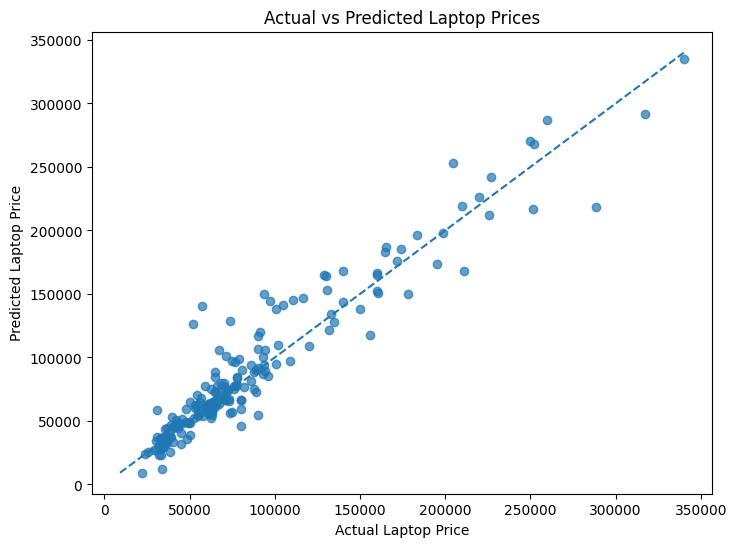

In [128]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line: perfect predictions
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Laptop Price")
plt.ylabel("Predicted Laptop Price")
plt.title("Actual vs Predicted Laptop Prices")

#### Evaluate the improved model using MAE, MSE, RMSE, and R-squared

In [129]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 11490.16
Mean Squared Error (MSE): 324600910.35
Root Mean Squared Error (RMSE): 18016.68
R² Score: 0.9037
